# Real-data extension: raw returns with an estimated return-mean parameter

This notebook implements the cleaner real-data extension of the stochastic volatility model. Instead of demeaning returns as a preprocessing step, we directly model the observed raw return as

$$
R_j = a + \exp(X_j/2)\eta_j, \qquad \eta_j\sim N(0,1),
$$

with latent state dynamics

$$
X_{j+1}=\mu+\phi(X_j-\mu)+\sigma_X\xi_{j+1}, \qquad \xi_{j+1}\sim N(0,1).
$$

Thus

$$
R_j \mid X_j=x \sim N(a,\exp(x)).
$$

The parameter vector is now

$$
\theta=(a,\mu,\phi,\sigma_X).
$$

The parameter $a$ is the constant return mean. The latent state $X_j$ remains the **log conditional variance** of returns around that mean, and $\exp(X_j/2)$ remains the conditional volatility.

The model is estimated from **returns only** by maximizing a bootstrap particle-filter estimate of the return likelihood. Realized volatility, if present in the dataset, is used only as an optional external proxy comparison after filtering. It is not used for parameter estimation and not used in the particle-filter weights.

In [1]:
# Imports
from pathlib import Path
import zipfile
import math
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.precision", 6)

## 1. Configuration

The defaults are chosen to run reasonably quickly. For a final robustness check, you can increase `ESTIMATION_PARTICLES`, `ESTIMATION_WINDOW`, and `FINAL_PARTICLES`.

Important: the realized-volatility column is optional and is used only in the last comparison section.

In [2]:
# Data file candidates. Put the zip next to this notebook, or update these paths.
DATA_ZIP_CANDIDATES = [
    Path("spx_real_data_extension_cleaned.zip"),
    Path("/mnt/data/spx_real_data_extension_cleaned.zip"),
    Path("/mnt/data/real_data_extension/spx_real_data_extension_cleaned.zip"),
]

# Observed return column used by the model.
RETURN_COL = "open_to_close_return"

# Optional external proxy only. Not used by estimation or filtering.
RV_PROXY_COL = "realized_volatility_5min_subsampled"

# Parameters are estimated on the training period using only returns.
TRAIN_END_DATE = "2015-12-31"

# Particle likelihood estimation settings.
ESTIMATION_PARTICLES = 500
ESTIMATION_WINDOW = 1200       # set None to use all training returns; larger is slower
ESTIMATION_SEED = 20260526
OPTIMIZER_MAXITER = 50

# Final filtering settings after estimating theta.
FINAL_PARTICLES = 2500
FINAL_FILTER_SEED = 20260527

# Particle-size sensitivity settings.
RUN_PARTICLE_SIZE_SENSITIVITY = True
SENSITIVITY_PARTICLES = [500, 1500, 2500]

# Output directories.
OUTPUT_DIR = Path("raw_return_mean_parameter_outputs")
FIGURE_DIR = Path("raw_return_mean_parameter_figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

## 2. Load SPX raw returns

The particle filter observes only the raw return series $R_j$. We keep the realized-volatility column only for the optional final comparison.

In [3]:
def find_data_zip(candidates):
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Could not find spx_real_data_extension_cleaned.zip. "
        "Put the zip file in the same folder as this notebook, or update DATA_ZIP_CANDIDATES."
    )


def load_spx_cleaned_zip(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        csv_names = [name for name in z.namelist() if name.endswith(".csv")]
        preferred = [name for name in csv_names if "spx_returns_realized_volatility" in name]
        if preferred:
            csv_name = preferred[0]
        elif csv_names:
            csv_name = csv_names[0]
        else:
            raise ValueError("No CSV file found inside zip.")
        with z.open(csv_name) as f:
            df = pd.read_csv(f)
    return df, csv_name


data_zip = find_data_zip(DATA_ZIP_CANDIDATES)
df_raw, csv_inside_zip = load_spx_cleaned_zip(data_zip)

print(f"Loaded zip: {data_zip}")
print(f"CSV inside zip: {csv_inside_zip}")
print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Loaded zip: spx_real_data_extension_cleaned.zip
CSV inside zip: spx_returns_realized_volatility_2000_2021.csv
Raw shape: (5358, 14)


,date,symbol,open_to_close_return,close_to_close_log_return,open_price,close_price,realized_variance_5min_subsampled,realized_volatility_5min_subsampled,realized_variance_5min,realized_volatility_5min,realized_kernel_parzen,realized_kernel_volatility_parzen,num_intraday_observations,log_realized_variance_5min_subsampled
0,2000-01-03,.SPX,-0.011602,NaN,1471.21,1454.24,0.000141,0.011867,0.000141,0.011867,0.000340,0.018437,1554.0,-8.868065
1,2000-01-04,.SPX,-0.035102,-0.038711,1449.00,1399.02,0.000224,0.014971,0.000224,0.014971,0.000215,0.014672,1564.0,-8.403279
2,2000-01-05,.SPX,0.004625,0.002192,1395.62,1402.09,0.000314,0.017728,0.000314,0.017728,0.000163,0.012758,1552.0,-8.065219
3,2000-01-06,.SPX,0.002991,0.000692,1398.87,1403.06,0.000131,0.011437,0.000131,0.011437,0.000067,0.008161,1561.0,-8.941767
4,2000-01-07,.SPX,0.026293,0.026571,1403.45,1440.84,0.000094,0.009676,0.000094,0.009676,0.000215,0.014679,1540.0,-9.276248


In [4]:
# Basic cleaning.
required_cols = ["date", RETURN_COL]
missing = [c for c in required_cols if c not in df_raw.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df_raw.copy()
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").dropna(subset=[RETURN_COL]).reset_index(drop=True)
df["r"] = df[RETURN_COL].astype(float)

train_end = pd.Timestamp(TRAIN_END_DATE)
train_mask = df["date"] <= train_end
if train_mask.sum() < 50:
    raise ValueError("Training period is too short. Adjust TRAIN_END_DATE.")

print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Rows: {len(df)}")
print(f"Training rows through {TRAIN_END_DATE}: {train_mask.sum()}")
print(f"Training raw-return mean: {df.loc[train_mask, 'r'].mean():.6e}")
print(f"Training raw-return std:  {df.loc[train_mask, 'r'].std():.6e}")

cols_to_show = ["date", RETURN_COL, "r"]
if RV_PROXY_COL in df.columns:
    cols_to_show.append(RV_PROXY_COL)
df[cols_to_show].head()

Date range: 2000-01-03 to 2021-05-18
Rows: 5358
Training rows through 2015-12-31: 4015
Training raw-return mean: 5.800017e-05
Training raw-return std:  1.193509e-02


,date,open_to_close_return,r,realized_volatility_5min_subsampled
0,2000-01-03,-0.011602,-0.011602,0.011867
1,2000-01-04,-0.035102,-0.035102,0.014971
2,2000-01-05,0.004625,0.004625,0.017728
3,2000-01-06,0.002991,0.002991,0.011437
4,2000-01-07,0.026293,0.026293,0.009676


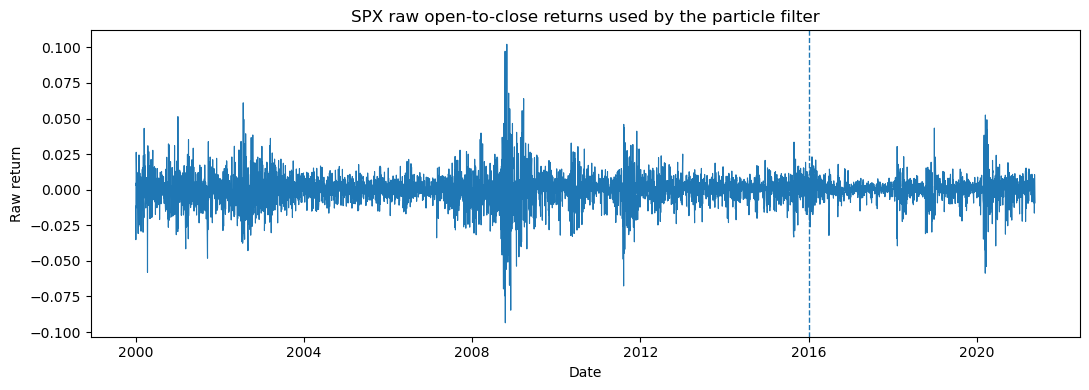

In [5]:
plt.figure(figsize=(11, 4))
plt.plot(df["date"], df["r"], linewidth=0.8)
plt.axvline(train_end, linestyle="--", linewidth=1)
plt.title("SPX raw open-to-close returns used by the particle filter")
plt.xlabel("Date")
plt.ylabel("Raw return")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_raw_returns_used_by_filter.png", dpi=160)
plt.show()

## 3. Particle-filter likelihood with return mean $a$

For a candidate parameter vector $\theta=(a,\mu,\phi,\sigma_X)$, the observation likelihood is

$$
g_j(x;\theta)
= f(r_j\mid X_j=x)
= \frac{1}{\sqrt{2\pi\exp(x)}}
\exp\left\{-\frac{(r_j-a)^2}{2\exp(x)}\right\}.
$$

The bootstrap particle filter estimates each predictive likelihood contribution by the average of the unnormalized weights:

$$
\widehat p_\theta(r_j\mid r_{1:j-1})
=
\frac1N\sum_{n=1}^N g_j(\widehat X_j^{(n)};\theta).
$$

Then

$$
\widehat{\log L}(\theta)
=
\sum_{j=1}^J
\log\left[
\frac1N\sum_{n=1}^N g_j(\widehat X_j^{(n)};\theta)
\right].
$$

In [6]:
LOG_2PI = np.log(2.0 * np.pi)


def sv_loglik_observation_with_mean(r, a, x):
    """log f(r | X=x) for r | x ~ N(a, exp(x))."""
    x_safe = np.clip(x, -50.0, 30.0)
    residual = r - a
    return -0.5 * LOG_2PI - 0.5 * x_safe - 0.5 * residual * residual * np.exp(-x_safe)


def logmeanexp(values):
    """Stable log(mean(exp(values)))."""
    m = np.max(values)
    return m + np.log(np.mean(np.exp(values - m)))


def systematic_resample_indices(weights, u):
    """Systematic resampling. u is one Uniform(0,1) draw."""
    N = len(weights)
    positions = (u + np.arange(N)) / N
    cumsum = np.cumsum(weights)
    cumsum[-1] = 1.0
    return np.searchsorted(cumsum, positions, side="left")


def multinomial_resample_indices(weights, rng):
    return rng.choice(len(weights), size=len(weights), replace=True, p=weights)


def make_common_random_numbers(T, N, seed):
    rng = np.random.default_rng(seed)
    return {
        "z0": rng.standard_normal(N),
        "eps": rng.standard_normal((T, N)),
        "u": rng.random(T),
    }


def validate_theta(a, mu, phi, sigma_x):
    return (
        np.all(np.isfinite([a, mu, phi, sigma_x]))
        and (-0.999 < phi < 0.999)
        and (sigma_x > 0)
    )


def pf_loglik_raw_return_crn(r, a, mu, phi, sigma_x, crn):
    """
    Bootstrap particle-filter log-likelihood estimate for raw returns.

    This function uses only raw returns r. Realized volatility is not an input.
    Common random numbers make the simulated objective more stable across parameter values.
    """
    if not validate_theta(a, mu, phi, sigma_x):
        return -np.inf

    T = len(r)
    N = len(crn["z0"])
    if crn["eps"].shape[0] < T:
        raise ValueError("Common-random-number eps array is shorter than r.")

    stationary_var = sigma_x**2 / (1.0 - phi**2)
    if (not np.isfinite(stationary_var)) or stationary_var <= 0 or stationary_var > 500.0:
        return -np.inf

    particles = mu + np.sqrt(stationary_var) * crn["z0"]
    loglik = 0.0

    for j in range(T):
        # Bootstrap proposal: transition p(x_j | x_{j-1}).
        x_hat = mu + phi * (particles - mu) + sigma_x * crn["eps"][j]

        # Unnormalized log weights are observation log-likelihoods.
        logw = sv_loglik_observation_with_mean(r[j], a, x_hat)

        # Predictive likelihood estimate: mean of unnormalized weights.
        log_pred = logmeanexp(logw)
        if not np.isfinite(log_pred):
            return -np.inf
        loglik += log_pred

        # Normalize weights for resampling.
        log_sum_w = log_pred + np.log(N)
        weights = np.exp(logw - log_sum_w)
        weights_sum = weights.sum()
        if (not np.isfinite(weights_sum)) or weights_sum <= 0:
            return -np.inf
        weights = weights / weights_sum

        idx = systematic_resample_indices(weights, crn["u"][j])
        particles = x_hat[idx]

    return float(loglik)

## 4. Estimate $\theta=(a,\mu,\phi,\sigma_X)$ from returns only

We use a simple practical approach:

1. Choose initial values from a coarse grid over $\phi$ and $\sigma_X$, with $a$ initialized at the training-sample return mean.
2. Set the starting $\mu$ so that the stationary unconditional variance roughly matches the sample return variance.
3. Run bounded Powell optimization on the particle log-likelihood.

This is a simulated-likelihood estimate, not a full Bayesian particle MCMC analysis.

In [7]:
r_train_full = df.loc[train_mask, "r"].to_numpy(dtype=float)

if ESTIMATION_WINDOW is None:
    r_est = r_train_full
else:
    r_est = r_train_full[: min(ESTIMATION_WINDOW, len(r_train_full))]

sample_mean = float(np.mean(r_est))
sample_std = float(np.std(r_est, ddof=1))
sample_var = float(np.var(r_est, ddof=1))
sample_log_var = float(np.log(sample_var))

print(f"Estimation observations used: {len(r_est)}")
print(f"Sample mean of estimation returns: {sample_mean:.6e}")
print(f"Sample std of estimation returns:  {sample_std:.6e}")
print(f"Sample variance: {sample_var:.6e}")
print(f"log(sample variance): {sample_log_var:.6f}")

crn_est = make_common_random_numbers(T=len(r_est), N=ESTIMATION_PARTICLES, seed=ESTIMATION_SEED)

# Bounds: wide enough for daily returns, but finite to avoid pathological particle-likelihood values.
a_bounds = (sample_mean - 0.5 * sample_std, sample_mean + 0.5 * sample_std)
mu_bounds = (sample_log_var - 8.0, sample_log_var + 4.0)
phi_bounds = (0.50, 0.995)
sigma_bounds = (0.02, 1.00)
bounds = [a_bounds, mu_bounds, phi_bounds, sigma_bounds]

print("Parameter bounds:")
print(f"a:       {a_bounds}")
print(f"mu:      {mu_bounds}")
print(f"phi:     {phi_bounds}")
print(f"sigma_X: {sigma_bounds}")


def implied_mu_from_unconditional_return_variance(phi, sigma_x, target_log_var):
    """
    If X is stationary normal with variance C, then E[exp(X)] = exp(mu + C/2).
    Matching this to the sample return variance gives mu = log(var_r) - C/2.
    This is only used to generate starting values.
    """
    C = sigma_x**2 / (1.0 - phi**2)
    return target_log_var - 0.5 * C

# Coarse starting grid.
phi_grid = np.array([0.75, 0.85, 0.92, 0.97, 0.985])
sigma_grid = np.array([0.05, 0.10, 0.20, 0.35, 0.50])

grid_rows = []
for phi in phi_grid:
    for sx in sigma_grid:
        a0 = sample_mean
        mu0 = implied_mu_from_unconditional_return_variance(phi, sx, sample_log_var)
        mu0 = float(np.clip(mu0, mu_bounds[0], mu_bounds[1]))
        ll = pf_loglik_raw_return_crn(r_est, a0, mu0, phi, sx, crn_est)
        grid_rows.append({"a": a0, "mu": mu0, "phi": phi, "sigma_x": sx, "loglik": ll})

grid_df = pd.DataFrame(grid_rows).sort_values("loglik", ascending=False).reset_index(drop=True)
grid_df.to_csv(OUTPUT_DIR / "raw_return_mean_grid_search_table.csv", index=False)
grid_df.head(10)

Estimation observations used: 1200
Sample mean of estimation returns: -3.074099e-04
Sample std of estimation returns:  1.230058e-02
Sample variance: 1.513044e-04
log(sample variance): -8.796217
Parameter bounds:
a:       (-0.006457701968934958, 0.005842882265220648)
mu:      (-16.796217038039913, -4.796217038039911)
phi:     (0.5, 0.995)
sigma_X: (0.02, 1.0)


,a,mu,phi,sigma_x,loglik
0,-0.000307,-8.964143,0.985,0.10,3687.028300
1,-0.000307,-9.134627,0.970,0.20,3682.521482
2,-0.000307,-9.467921,0.985,0.20,3679.029697
3,-0.000307,-8.880819,0.970,0.10,3677.781293
4,-0.000307,-8.926425,0.920,0.20,3671.019166
5,-0.000307,-9.194980,0.920,0.35,3667.643709
6,-0.000307,-8.838199,0.985,0.05,3665.418172
7,-0.000307,-9.016938,0.850,0.35,3661.503003
8,-0.000307,-9.832596,0.970,0.35,3656.266256
9,-0.000307,-9.246667,0.850,0.50,3649.759507


In [8]:
start = grid_df.loc[0, ["a", "mu", "phi", "sigma_x"]].to_numpy(dtype=float)
print("Starting value from coarse grid:")
print({"a": start[0], "mu": start[1], "phi": start[2], "sigma_x": start[3]})

objective_trace = []


def neg_loglik_objective(params):
    a, mu, phi, sigma_x = params
    in_bounds = (
        a_bounds[0] <= a <= a_bounds[1]
        and mu_bounds[0] <= mu <= mu_bounds[1]
        and phi_bounds[0] <= phi <= phi_bounds[1]
        and sigma_bounds[0] <= sigma_x <= sigma_bounds[1]
    )
    if not in_bounds:
        return 1e12
    ll = pf_loglik_raw_return_crn(r_est, a, mu, phi, sigma_x, crn_est)
    val = -ll if np.isfinite(ll) else 1e12
    objective_trace.append({"a": a, "mu": mu, "phi": phi, "sigma_x": sigma_x, "neg_loglik": val})
    return val

opt_result = minimize(
    neg_loglik_objective,
    start,
    method="Powell",
    bounds=bounds,
    options={"maxiter": OPTIMIZER_MAXITER, "xtol": 1e-3, "ftol": 1e-3, "disp": True},
)

theta_hat = {
    "a": float(opt_result.x[0]),
    "mu": float(opt_result.x[1]),
    "phi": float(opt_result.x[2]),
    "sigma_x": float(opt_result.x[3]),
    "estimation_loglik": float(-opt_result.fun),
    "optimization_success": bool(opt_result.success),
    "optimization_message": str(opt_result.message),
    "estimation_particles": ESTIMATION_PARTICLES,
    "estimation_observations": len(r_est),
    "estimation_seed": ESTIMATION_SEED,
    "train_end_date": TRAIN_END_DATE,
}

theta_hat_df = pd.DataFrame([theta_hat])
theta_hat_df.to_csv(OUTPUT_DIR / "raw_return_mean_parameter_estimates.csv", index=False)

trace_df = pd.DataFrame(objective_trace)
trace_df.to_csv(OUTPUT_DIR / "raw_return_mean_optimizer_trace.csv", index=False)

display(theta_hat_df)

Starting value from coarse grid:
{'a': np.float64(-0.0003074098518571549), 'mu': np.float64(-8.964143150550406), 'phi': np.float64(0.985), 'sigma_x': np.float64(0.1)}
Optimization terminated successfully.
         Current function value: -3688.505701
         Iterations: 1
         Function evaluations: 55


,a,mu,phi,sigma_x,estimation_loglik,optimization_success,optimization_message,estimation_particles,estimation_observations,estimation_seed,train_end_date
0,-0.00003,-8.973831,0.987451,0.094581,3688.505701,True,Optimization terminated successfully.,500,1200,20260526,2015-12-31


## 5. Final bootstrap particle filter using raw returns

After estimating $\theta$, we run the particle filter again. The update uses only the return likelihood $f(r_j\mid X_j=x)$.

The main filtered estimates are

$$
\widehat m_j \approx E[X_j\mid R_{1:j}],
$$

$$
\widehat v_j \approx E[\exp(X_j)\mid R_{1:j}],
$$

$$
\widehat\sigma_j \approx E[\exp(X_j/2)\mid R_{1:j}].
$$

In [9]:
def bootstrap_particle_filter_raw_return(r, a, mu, phi, sigma_x, N=2000, seed=123, resampling="systematic"):
    """Bootstrap particle filter for raw returns R_j | X_j=x ~ N(a, exp(x))."""
    if not validate_theta(a, mu, phi, sigma_x):
        raise ValueError("Invalid theta.")

    rng = np.random.default_rng(seed)
    T = len(r)
    stationary_var = sigma_x**2 / (1.0 - phi**2)
    if stationary_var <= 0 or not np.isfinite(stationary_var):
        raise ValueError("Invalid stationary variance.")

    particles = rng.normal(loc=mu, scale=np.sqrt(stationary_var), size=N)

    filtered_logvar = np.empty(T)
    filtered_variance = np.empty(T)
    filtered_volatility = np.empty(T)
    ess = np.empty(T)
    loglik_increments = np.empty(T)

    for j in range(T):
        eps = rng.standard_normal(N)
        x_hat = mu + phi * (particles - mu) + sigma_x * eps
        logw = sv_loglik_observation_with_mean(r[j], a, x_hat)

        log_pred = logmeanexp(logw)
        loglik_increments[j] = log_pred

        log_sum_w = log_pred + np.log(N)
        weights = np.exp(logw - log_sum_w)
        weights = weights / weights.sum()

        ess[j] = 1.0 / np.sum(weights**2)
        x_clip = np.clip(x_hat, -50.0, 30.0)
        filtered_logvar[j] = np.sum(weights * x_hat)
        filtered_variance[j] = np.sum(weights * np.exp(x_clip))
        filtered_volatility[j] = np.sum(weights * np.exp(x_clip / 2.0))

        if resampling == "systematic":
            idx = systematic_resample_indices(weights, rng.random())
        elif resampling == "multinomial":
            idx = multinomial_resample_indices(weights, rng)
        else:
            raise ValueError("resampling must be 'systematic' or 'multinomial'.")
        particles = x_hat[idx]

    return {
        "filtered_logvar": filtered_logvar,
        "filtered_variance": filtered_variance,
        "filtered_volatility": filtered_volatility,
        "ess": ess,
        "relative_ess": ess / N,
        "loglik_increments": loglik_increments,
        "loglik": float(np.sum(loglik_increments)),
        "N": N,
        "seed": seed,
    }


r_all = df["r"].to_numpy(dtype=float)

pf_result = bootstrap_particle_filter_raw_return(
    r_all,
    a=theta_hat["a"],
    mu=theta_hat["mu"],
    phi=theta_hat["phi"],
    sigma_x=theta_hat["sigma_x"],
    N=FINAL_PARTICLES,
    seed=FINAL_FILTER_SEED,
    resampling="systematic",
)

print(f"Final PF log-likelihood estimate: {pf_result['loglik']:.3f}")
print(f"Final PF particles: {pf_result['N']}")

Final PF log-likelihood estimate: 17791.840
Final PF particles: 2500


In [10]:
# Store filtering results.
result_df = df[["date", RETURN_COL, "r"]].copy()
result_df["estimated_return_mean_a"] = theta_hat["a"]
result_df["return_residual_r_minus_a"] = result_df["r"] - theta_hat["a"]
result_df["filtered_logvar"] = pf_result["filtered_logvar"]
result_df["filtered_variance_E_exp_X"] = pf_result["filtered_variance"]
result_df["filtered_volatility_E_exp_X_over_2"] = pf_result["filtered_volatility"]
result_df["ess"] = pf_result["ess"]
result_df["relative_ess"] = pf_result["relative_ess"]
result_df["loglik_increment"] = pf_result["loglik_increments"]
result_df["is_training_period"] = result_df["date"] <= train_end

if RV_PROXY_COL in df.columns:
    result_df[RV_PROXY_COL] = df[RV_PROXY_COL]
    rv_proxy = np.asarray(df[RV_PROXY_COL], dtype=float)
    result_df["log_realized_variance_proxy"] = np.log(np.maximum(rv_proxy**2, 1e-300))

result_df.to_csv(OUTPUT_DIR / "raw_return_mean_particle_filter_results.csv", index=False)
result_df.head()

,date,open_to_close_return,r,estimated_return_mean_a,return_residual_r_minus_a,filtered_logvar,filtered_variance_E_exp_X,filtered_volatility_E_exp_X_over_2,ess,relative_ess,loglik_increment,is_training_period,realized_volatility_5min_subsampled,log_realized_variance_proxy
0,2000-01-03,-0.011602,-0.011602,-0.00003,-0.011571,-8.930629,0.000154,0.011945,2459.342027,0.983737,2.951503,True,0.011867,-8.868065
1,2000-01-04,-0.035102,-0.035102,-0.00003,-0.035071,-8.252038,0.000287,0.016530,834.461105,0.333784,-0.174790,True,0.014971,-8.403279
2,2000-01-05,0.004625,0.004625,-0.00003,0.004656,-8.340041,0.000262,0.015810,2409.000560,0.963600,3.182600,True,0.017728,-8.065219
3,2000-01-06,0.002991,0.002991,-0.00003,0.003021,-8.435640,0.000238,0.015070,2399.373312,0.959749,3.255062,True,0.011437,-8.941767
4,2000-01-07,0.026293,0.026293,-0.00003,0.026323,-8.264731,0.000279,0.016370,2134.245052,0.853698,1.664419,True,0.009676,-9.276248


In [11]:
summary_metrics = {
    "n_observations": len(result_df),
    "n_training_observations": int(result_df["is_training_period"].sum()),
    "a_hat": theta_hat["a"],
    "mu_hat": theta_hat["mu"],
    "phi_hat": theta_hat["phi"],
    "sigma_x_hat": theta_hat["sigma_x"],
    "final_particles": FINAL_PARTICLES,
    "final_loglik_estimate": pf_result["loglik"],
    "mean_filtered_volatility": float(result_df["filtered_volatility_E_exp_X_over_2"].mean()),
    "median_filtered_volatility": float(result_df["filtered_volatility_E_exp_X_over_2"].median()),
    "mean_relative_ess": float(result_df["relative_ess"].mean()),
    "min_relative_ess": float(result_df["relative_ess"].min()),
}
summary_df = pd.DataFrame([summary_metrics])
summary_df.to_csv(OUTPUT_DIR / "raw_return_mean_filter_summary_metrics.csv", index=False)
display(summary_df)

,n_observations,n_training_observations,a_hat,mu_hat,phi_hat,sigma_x_hat,final_particles,final_loglik_estimate,mean_filtered_volatility,median_filtered_volatility,mean_relative_ess,min_relative_ess
0,5358,4015,-0.00003,-8.973831,0.987451,0.094581,2500,17791.839867,0.009727,0.008622,0.958606,0.001483


## 6. Return-only filtering diagnostics

These plots are based only on raw returns and the return-only particle filter.

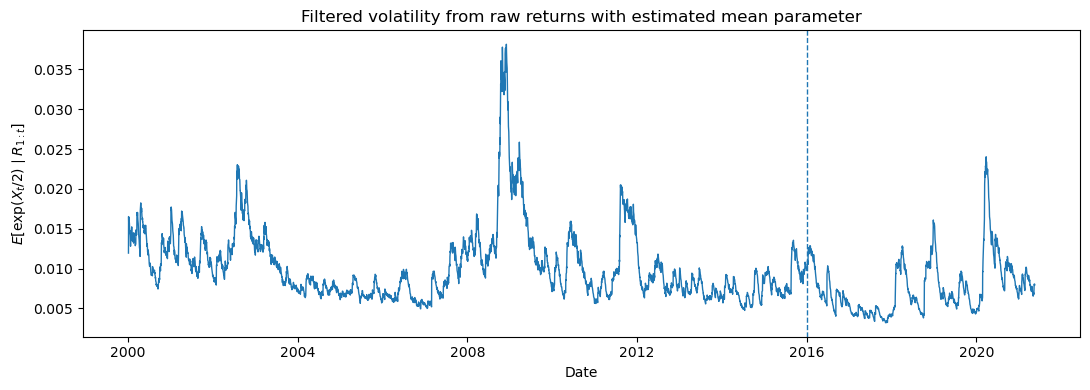

In [12]:
plt.figure(figsize=(11, 4))
plt.plot(result_df["date"], result_df["filtered_volatility_E_exp_X_over_2"], linewidth=1.0)
plt.axvline(train_end, linestyle="--", linewidth=1)
plt.title("Filtered volatility from raw returns with estimated mean parameter")
plt.xlabel("Date")
plt.ylabel(r"$E[\exp(X_t/2)\mid R_{1:t}]$")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_filtered_volatility_raw_return_mean_parameter.png", dpi=160)
plt.show()

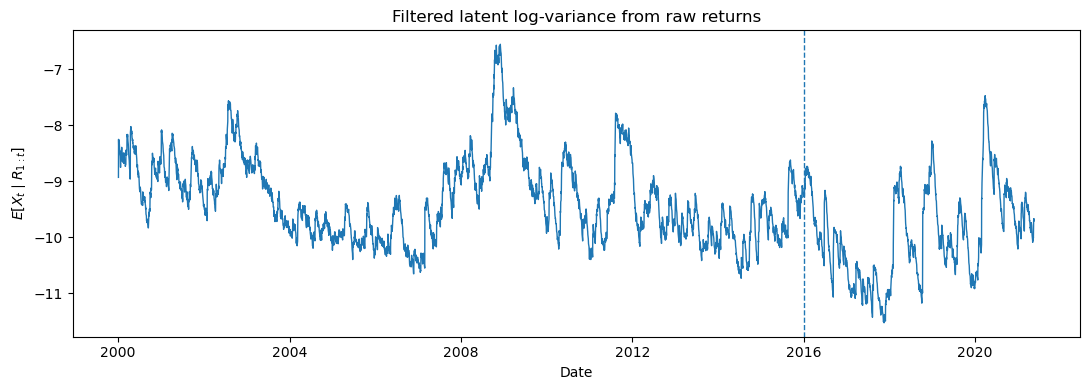

In [13]:
plt.figure(figsize=(11, 4))
plt.plot(result_df["date"], result_df["filtered_logvar"], linewidth=1.0)
plt.axvline(train_end, linestyle="--", linewidth=1)
plt.title("Filtered latent log-variance from raw returns")
plt.xlabel("Date")
plt.ylabel(r"$E[X_t\mid R_{1:t}]$")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_filtered_logvar_raw_return_mean_parameter.png", dpi=160)
plt.show()

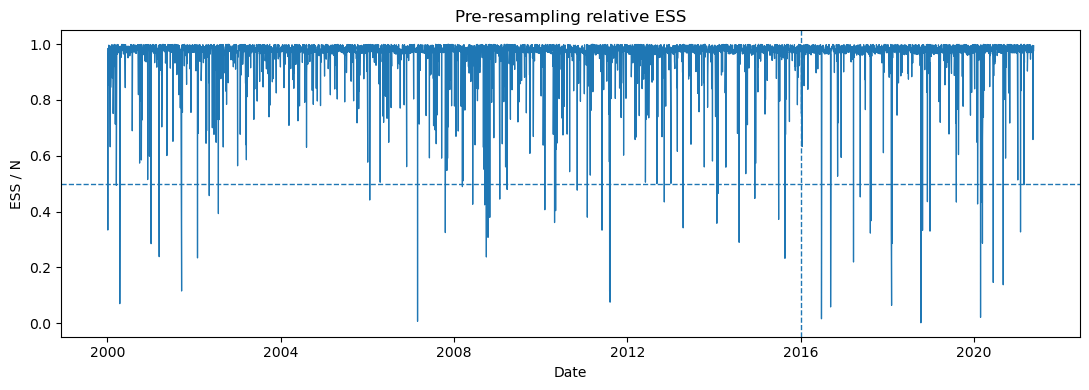

In [14]:
plt.figure(figsize=(11, 4))
plt.plot(result_df["date"], result_df["relative_ess"], linewidth=0.9)
plt.axhline(0.5, linestyle="--", linewidth=1)
plt.axvline(train_end, linestyle="--", linewidth=1)
plt.title("Pre-resampling relative ESS")
plt.xlabel("Date")
plt.ylabel("ESS / N")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_relative_ess_raw_return_mean_parameter.png", dpi=160)
plt.show()

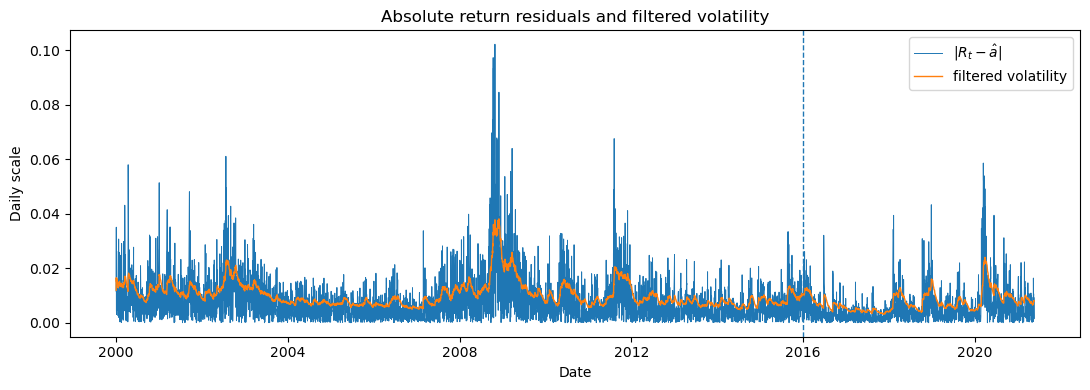

In [15]:
plt.figure(figsize=(11, 4))
plt.plot(result_df["date"], np.abs(result_df["return_residual_r_minus_a"]), linewidth=0.7, label=r"$|R_t-\hat a|$")
plt.plot(result_df["date"], result_df["filtered_volatility_E_exp_X_over_2"], linewidth=1.0, label="filtered volatility")
plt.axvline(train_end, linestyle="--", linewidth=1)
plt.title("Absolute return residuals and filtered volatility")
plt.xlabel("Date")
plt.ylabel("Daily scale")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_abs_residuals_and_filtered_volatility.png", dpi=160)
plt.show()

## 7. Optional external comparison with realized volatility proxy

This section is optional and does **not** affect estimation or filtering. It compares the return-only filtered volatility with a realized-volatility proxy.

Interpretation: this is agreement with an external proxy, not error against the true latent volatility.

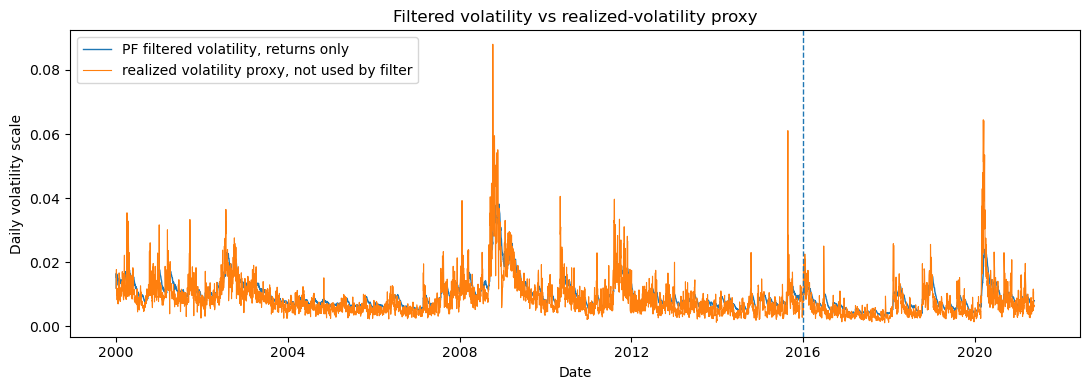

In [16]:
if RV_PROXY_COL in result_df.columns:
    plt.figure(figsize=(11, 4))
    plt.plot(result_df["date"], result_df["filtered_volatility_E_exp_X_over_2"], linewidth=1.0, label="PF filtered volatility, returns only")
    plt.plot(result_df["date"], result_df[RV_PROXY_COL], linewidth=0.8, label="realized volatility proxy, not used by filter")
    plt.axvline(train_end, linestyle="--", linewidth=1)
    plt.title("Filtered volatility vs realized-volatility proxy")
    plt.xlabel("Date")
    plt.ylabel("Daily volatility scale")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "06_filtered_volatility_vs_rv_proxy_optional.png", dpi=160)
    plt.show()
else:
    print(f"No {RV_PROXY_COL!r} column available; skipping optional proxy plot.")

,sample,n,correlation_with_rv_proxy,mae_vs_rv_proxy,rmse_vs_rv_proxy,mean_filtered_volatility,mean_rv_proxy
0,all_available_dates,5358,0.785271,0.002756,0.004023,0.009727,0.008513
1,test_period_only,1343,0.730479,0.002675,0.004240,0.007703,0.006762


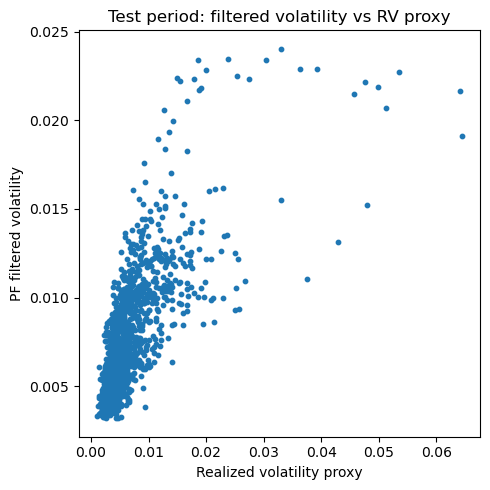

In [17]:
if RV_PROXY_COL in result_df.columns:
    eval_df = result_df.dropna(subset=[RV_PROXY_COL, "filtered_volatility_E_exp_X_over_2"]).copy()
    test_eval_df = eval_df[eval_df["date"] > train_end].copy()

    def proxy_metrics(data, label):
        pf = data["filtered_volatility_E_exp_X_over_2"].to_numpy()
        rv = data[RV_PROXY_COL].to_numpy()
        return {
            "sample": label,
            "n": len(data),
            "correlation_with_rv_proxy": float(np.corrcoef(pf, rv)[0, 1]) if len(data) > 1 else np.nan,
            "mae_vs_rv_proxy": float(np.mean(np.abs(pf - rv))) if len(data) > 0 else np.nan,
            "rmse_vs_rv_proxy": float(np.sqrt(np.mean((pf - rv) ** 2))) if len(data) > 0 else np.nan,
            "mean_filtered_volatility": float(np.mean(pf)) if len(data) > 0 else np.nan,
            "mean_rv_proxy": float(np.mean(rv)) if len(data) > 0 else np.nan,
        }

    metrics_df = pd.DataFrame([
        proxy_metrics(eval_df, "all_available_dates"),
        proxy_metrics(test_eval_df, "test_period_only"),
    ])
    metrics_df.to_csv(OUTPUT_DIR / "optional_rv_proxy_comparison_metrics.csv", index=False)
    display(metrics_df)

    plt.figure(figsize=(5, 5))
    plt.scatter(test_eval_df[RV_PROXY_COL], test_eval_df["filtered_volatility_E_exp_X_over_2"], s=10)
    plt.title("Test period: filtered volatility vs RV proxy")
    plt.xlabel("Realized volatility proxy")
    plt.ylabel("PF filtered volatility")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "07_scatter_test_filtered_volatility_vs_rv_proxy.png", dpi=160)
    plt.show()
else:
    print("No realized-volatility proxy column; skipping proxy metrics.")

## 8. Particle-size sensitivity

This checks whether the return-only filtered-volatility path is reasonably stable as the number of particles changes.

,N,loglik,mean_relative_ess,min_relative_ess,mean_filtered_volatility,correlation_with_final_path
0,500,17782.678336,0.959146,0.008422,0.009705,0.998541
1,1500,17788.587214,0.958577,0.004772,0.009715,0.998888
2,2500,17794.076714,0.958409,0.003126,0.009730,0.999151


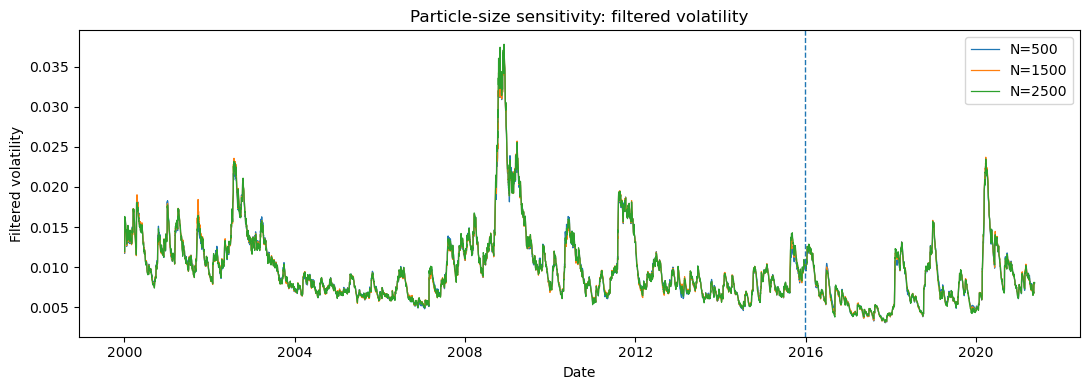

In [18]:
if RUN_PARTICLE_SIZE_SENSITIVITY:
    sensitivity_rows = []
    sensitivity_paths = {}

    for N in SENSITIVITY_PARTICLES:
        res_N = bootstrap_particle_filter_raw_return(
            r_all,
            a=theta_hat["a"],
            mu=theta_hat["mu"],
            phi=theta_hat["phi"],
            sigma_x=theta_hat["sigma_x"],
            N=N,
            seed=FINAL_FILTER_SEED + N,
            resampling="systematic",
        )
        sensitivity_paths[N] = res_N["filtered_volatility"]
        sensitivity_rows.append({
            "N": N,
            "loglik": res_N["loglik"],
            "mean_relative_ess": float(np.mean(res_N["relative_ess"])),
            "min_relative_ess": float(np.min(res_N["relative_ess"])),
            "mean_filtered_volatility": float(np.mean(res_N["filtered_volatility"])),
            "correlation_with_final_path": float(np.corrcoef(res_N["filtered_volatility"], pf_result["filtered_volatility"])[0, 1]),
        })

    sensitivity_df = pd.DataFrame(sensitivity_rows)
    sensitivity_df.to_csv(OUTPUT_DIR / "particle_size_sensitivity_metrics.csv", index=False)
    display(sensitivity_df)

    plt.figure(figsize=(11, 4))
    for N, path in sensitivity_paths.items():
        plt.plot(result_df["date"], path, linewidth=0.9, label=f"N={N}")
    plt.axvline(train_end, linestyle="--", linewidth=1)
    plt.title("Particle-size sensitivity: filtered volatility")
    plt.xlabel("Date")
    plt.ylabel("Filtered volatility")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "08_particle_size_sensitivity.png", dpi=160)
    plt.show()
else:
    print("Particle-size sensitivity disabled.")

## 9. Package outputs

The output files include parameter estimates, filtering results, optional proxy-comparison metrics, and figures.

In [19]:
# Create a zip package of output CSVs and figures.
package_base = Path("raw_return_mean_parameter_real_data_extension_outputs")
package_zip = Path(str(package_base) + ".zip")

if package_zip.exists():
    package_zip.unlink()

# make_archive returns the full path without needing the .zip suffix.
shutil.make_archive(str(package_base), "zip", root_dir=Path("."), base_dir=str(OUTPUT_DIR))

# Add figures to the same zip.
with zipfile.ZipFile(package_zip, mode="a", compression=zipfile.ZIP_DEFLATED) as z:
    for fig_path in FIGURE_DIR.glob("*.png"):
        z.write(fig_path, arcname=str(FIGURE_DIR / fig_path.name))

print(f"Packaged outputs: {package_zip.resolve()}")
print("Key files:")
print(f"- {OUTPUT_DIR / 'raw_return_mean_parameter_estimates.csv'}")
print(f"- {OUTPUT_DIR / 'raw_return_mean_particle_filter_results.csv'}")
print(f"- {OUTPUT_DIR / 'raw_return_mean_filter_summary_metrics.csv'}")
print(f"- {FIGURE_DIR}/")

Packaged outputs: /Users/haochengsun/Desktop/Research/SMC Filtering Latent Volatility/raw_return_mean_parameter_real_data_extension_outputs.zip
Key files:
- raw_return_mean_parameter_outputs/raw_return_mean_parameter_estimates.csv
- raw_return_mean_parameter_outputs/raw_return_mean_particle_filter_results.csv
- raw_return_mean_parameter_outputs/raw_return_mean_filter_summary_metrics.csv
- raw_return_mean_parameter_figures/
